# RQ2：下游出发延误预测与解释

研究问题：上游飞机实际到达后，能否预测下游出发延误？本页依据本轮配置、模型 manifest 与实际指标解释结果，不重新训练，也不预设使用哪一组特征或算法。

In [1]:
ROOT = __import__('pathlib').Path.cwd()
RUN_DIR = ROOT / 'experiments/runs/R0025'

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

if "ROOT" not in globals():
    ROOT = Path.cwd()
    while not (ROOT / "scripts/build_features.py").exists():
        if ROOT.parent == ROOT:
            raise RuntimeError("请在 Airline-delay 仓库中运行 Notebook")
        ROOT = ROOT.parent
if "RUN_DIR" not in globals():
    candidates = [p for p in (ROOT / "experiments/runs").glob("R*")
                  if (p / "metrics.csv").exists() and (p / "model_manifest.json").exists()]
    if not candidates:
        raise RuntimeError("请先归档预测实验，或手动设置 RUN_DIR")
    RUN_DIR = max(candidates, key=lambda p: int(p.name[1:]))
TABLES = RUN_DIR / "tables"
FIGURES = RUN_DIR / "figures"
def table(name):
    return pd.read_csv(TABLES / name)
def figure(name):
    display(Image(filename=str(FIGURES / name)))
def receipt(name):
    return json.loads((RUN_DIR / name).read_text(encoding="utf-8"))
display(Markdown(f"**归档运行：{RUN_DIR.name}**。本 Notebook 读取该轮表格与图，不重新拟合模型。"))

**归档运行：R0025**。本 Notebook 读取该轮表格与图，不重新拟合模型。

In [3]:
config = receipt("config.json") if (RUN_DIR / "config.json").exists() else {}
model_manifest = receipt("model_manifest.json")
features = model_manifest.get("features", config.get("features", []))
group_name = model_manifest.get("feature_group", config.get("feature_group", "未登记"))
models = model_manifest.get("models", [])
display(Markdown(f"本轮信息组：**{group_name}**；阶段：**{config.get('stage', '未登记')}**；模型：**{', '.join(models)}**。"))
display(pd.DataFrame([{"development_only": model_manifest.get("development_only"),
                       "parent_run_id": config.get("parent_run_id"),
                       "change": config.get("change"), "include_baselines": model_manifest.get("include_baselines")}]))

本轮信息组：**G4B**；阶段：**P5-models**；模型：**rf_d16_l50**。

,development_only,parent_run_id,change,include_baselines
0,True,R0024,Replace depth-16 leaf-50 decision tree with re...,False


## 1. 时间折与成熟标签

开发使用 4→5、4–5→6、4–6→7 月 UTC 前向验证。训练预测时点及标签时点均须严格早于训练截止；最终测试只能在规则冻结后进行。下表记录本轮实际切分和评估 ID 哈希。

In [4]:
display(pd.read_csv(RUN_DIR / "split_audit.csv"))
display(pd.DataFrame([{key: model_manifest.get(key) for key in ["evaluation_rows", "evaluation_ids_sha256", "split_sha256", "development_only"]}]))

,fold,train_start,train_end_exclusive,validation_start,validation_end_exclusive,train_rows,validation_rows,excluded_immature_training_labels,max_train_prediction_time,max_train_label_time,min_validation_prediction_time,max_validation_prediction_time,train_id_sha256,validation_id_sha256,train_target_sha256,validation_target_sha256
0,2026-05,2026-04-01T00:00:00+00:00,2026-05-01T00:00:00+00:00,2026-05-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,553140,574571,1544,2026-04-30T23:30:00+00:00,2026-04-30T23:59:00+00:00,2026-05-01T00:00:00+00:00,2026-05-31T23:59:00+00:00,1d9c1c54be72084a627b3865b21fc94e9e93254c332782...,db70eb2f46beff2f44a0d978cce9dbd84b44dbb52b1e50...,5c386d0f0ee1fc6a9a99cf99f6182c2d58579a493e3408...,4127ab7e0a6298fa42539db1bbc74075047d578ec63df3...
1,2026-06,2026-04-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,1127717,561972,1538,2026-05-31T23:36:00+00:00,2026-05-31T23:59:00+00:00,2026-06-01T00:00:00+00:00,2026-06-30T23:59:00+00:00,a90b8697524811822601e389f6dcd6af7155f7a3d71e2a...,e96b8cf52f6698df4b45e9a05b14fa21ebb3e2bc1f61ab...,92e5c3e7e1944ae98416f68e3b23b51c470d00762f1187...,6f0f88b0e09b752f77db4007c4375cfdf7bdfbf30355f4...
2,2026-07,2026-04-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,2026-08-01T00:00:00+00:00,1689573,570548,1654,2026-06-30T23:29:00+00:00,2026-06-30T23:59:00+00:00,2026-07-01T00:00:00+00:00,2026-07-31T23:59:00+00:00,620f6bd533a0293c182707e431ac65134e28da7eb60cc3...,df7fcbba5aaedaa4b8e9d6a590fa9bfaf19de5ff4b9070...,3f44149b050fa6f382963ad2b9afca69b645b2bb61692b...,0533c6befc1f7beac3ebae6d421b6945f82253dc78b655...


,evaluation_rows,evaluation_ids_sha256,split_sha256,development_only
0,1707091,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,True


## 2. 本轮信息、算法与预处理

实际地面周转、下游实际出发及未来运营结果不能进入特征。朴素参照包括每折训练均值、中位数，以及上游非负到达延误原样传递；仅在本轮确实归档它们时展示比较。所有数据依赖的预处理均在训练折拟合。

In [5]:
categorical = set(model_manifest.get("categorical_features", []))
display(pd.DataFrame({"字段": features, "类型": ["类别" if name in categorical else "数值" for name in features]}))
display(pd.json_normalize(model_manifest.get("effective_preprocessing", {})))
display(pd.json_normalize({key: model_manifest.get(key) for key in ["models", "model_name", "model_type", "model_params"]}))
display(Markdown("上游到达延误：" + ("**已作为预测变量加入**。" if "upstream_arr_delay_minutes" in features else "**不在本轮模型特征清单中**。")))

,字段,类型
0,airport_id,类别
1,route,类别
2,downstream_airline,类别
3,aircraft_family,类别
4,downstream_distance,数值
...,...,...
60,taf_probability_rain_flag,数值
61,taf_probability_snow_flag,数值
62,taf_probability_thunder_flag,数值
63,taf_probability_segment_count,数值


,min_frequency,drop,sparse,categorical_imputation,numeric_imputation,numeric_scaling,unknown_categories
0,20,first,True,constant __MISSING__; keep_empty_features=True,median; add_indicator=True; keep_empty_feature...,"StandardScaler(with_mean=False), fixed across ...",infrequent_if_exist


,models,model_name,model_type,model_params.bootstrap,model_params.ccp_alpha,model_params.criterion,model_params.max_depth,model_params.max_features,model_params.max_leaf_nodes,model_params.max_samples,...,model_params.min_samples_leaf,model_params.min_samples_split,model_params.min_weight_fraction_leaf,model_params.monotonic_cst,model_params.n_estimators,model_params.n_jobs,model_params.oob_score,model_params.random_state,model_params.verbose,model_params.warm_start
0,[rf_d16_l50],rf_d16_l50,random_forest,True,0.0,squared_error,16,0.5,None,None,...,50,2,0.0,None,200,8,False,42,0,False


上游到达延误：**已作为预测变量加入**。

## 3. 各月与整体预测误差

MAE 为主要指标；RMSE 对大误差更敏感。预测统一非负截断。整体指标按全部评估行聚合绝对/平方误差，不能简单平均月折指标。是否改善还须检查评估 ID、切分和目标一致。

,model,fold,n,mae,rmse,target_ge15_share
0,rf_d16_l50,2026-05,574571,10.462333,36.124997,0.207785
411,rf_d16_l50,2026-06,561972,12.144760,41.169029,0.247952
826,rf_d16_l50,2026-07,570548,13.897443,47.281023,0.272265
1625,rf_d16_l50,overall,1707091,12.164276,41.765397,0.242558


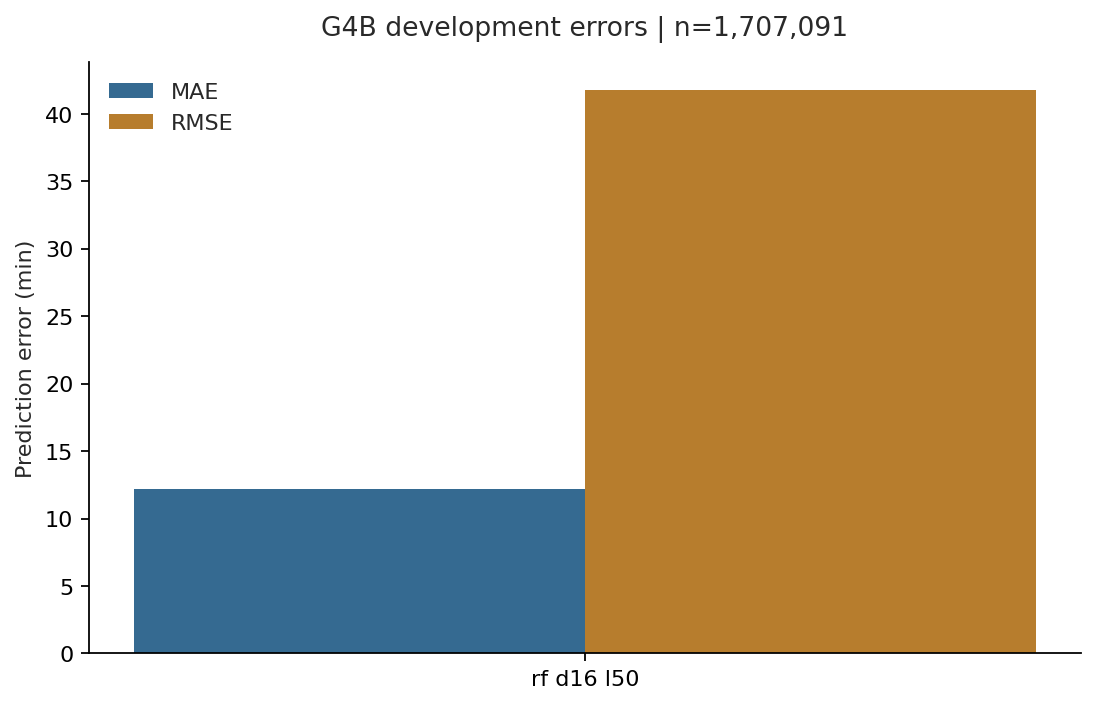

,n,mae,rmse
model,,,
rf_d16_l50,1707091,12.164276,41.765397


本轮未重算朴素基线。跨轮参照须使用下方已有比较文件，并确认相同评估 ID/切分。

In [6]:
metrics = pd.read_csv(RUN_DIR / "metrics.csv")
main = metrics.loc[metrics["group"].eq("all")]
columns = [name for name in ["model", "fold", "n", "mae", "rmse", "target_ge15_share"] if name in main]
display(main[columns])
if (FIGURES / "rq2_metric_comparison.png").exists():
    figure("rq2_metric_comparison.png")
pooled = main.loc[main.fold.eq("overall")].set_index("model")
comparison = pooled[["n", "mae", "rmse"]].copy()
for baseline in ["training_mean", "training_median", "carry_forward"]:
    if baseline in pooled.index:
        comparison[f"MAE改善_vs_{baseline}_分钟"] = pooled.loc[baseline, "mae"] - comparison.mae
display(comparison)
if not any(name in pooled.index for name in ["training_mean", "training_median", "carry_forward"]):
    display(Markdown("本轮未重算朴素基线。跨轮参照须使用下方已有比较文件，并确认相同评估 ID/切分。"))

## 4. 严重延误、隔夜与运行分组

普通/严重组按真实非负延误 <60 / ≥60 分钟预定义，是结果人群误差，不能用于事后挑选有利人群。各组同时列样本量；缺失或很小的组不强行解释。

In [7]:
overall = metrics.loc[metrics.fold.eq("overall")]
for group in ["severity", "overnight", "day_of_week", "scheduled_hour"]:
    display(Markdown(f"**{group}**"))
    display(overall.loc[overall["group"].eq(group), ["model", "value", "n", "mae", "rmse"]])
for group in ["airport", "airline", "aircraft_family", "aircraft_variant"]:
    grouped = overall.loc[overall["group"].eq(group)]
    for model, rows in grouped.groupby("model", sort=False):
        display(Markdown(f"**{group} / {model}（样本最多的 20 组）**"))
        display(rows[["value", "n", "mae", "rmse"]].sort_values("n", ascending=False).head(20))

**severity**

,model,value,n,mae,rmse
1659,rf_d16_l50,ordinary_lt60,1574341,7.283652,9.918249
1660,rf_d16_l50,severe_ge60,132750,70.045755,145.824259


**overnight**

,model,value,n,mae,rmse
1633,rf_d16_l50,False,1377745,12.031138,40.914930
1634,rf_d16_l50,True,329346,12.721228,45.149788


**day_of_week**

...

,value,n,mae,rmse
1515,13930,85951,12.609820,36.152922
1360,11292,79253,10.865879,30.354177
1290,10397,76296,12.074945,33.193500
1361,11298,72464,14.275446,36.760063
1457,12892,46444,10.657760,28.837572
1527,14107,45714,10.881154,32.667541
1572,14747,44035,10.399873,33.427047
1340,11057,41448,13.726960,38.493486
1455,12889,40458,10.789147,30.163217
1574,14771,37179,12.200568,38.943869


**airline / rf_d16_l50（样本最多的 20 组）**

,value,n,mae,rmse
1269,WN,349743,8.941386,19.382126
1261,DL,259774,11.505247,35.666601
1258,AA,232903,15.995354,63.128700
1267,OO,211816,11.875468,39.853202
1268,UA,201614,13.732993,42.620507
1259,AS,87165,9.063493,21.916271
1270,YX,84426,11.229103,37.043208
1264,MQ,81684,11.239322,42.096882
1260,B6,55338,14.266518,43.973859
1266,OH,54608,17.415415,68.744818


**aircraft_family / rf_d16_l50（样本最多的 20 组）**

,value,n,mae,rmse
1250,Boeing 737 NG,484155,11.167351,34.819179
1243,Airbus A320 family ceo,272749,14.816990,53.723511
1256,Embraer E170/E175,247979,10.525465,36.467879
1257,NaN,202314,11.767861,41.332038
1249,Boeing 737 MAX,172586,10.082512,28.796757
1255,Bombardier CRJ,143738,15.336873,55.501533
1244,Airbus A320 family neo,80232,13.110268,43.645184
1248,Boeing 717,36493,10.918637,35.344501
1242,Airbus A220,33438,13.267924,47.251278
1251,Boeing 757,25735,14.146945,43.365321


## 5. 直接前轮比较与证据

特征增量与算法差异分开比较，每轮只改变一个研究因素。只有同一评估样本、目标及切分下的差值才能作为直接改善证据。预测、模型、评估 ID 与配置保存在本轮归档；下方只显示已有比较文件，不自动重算或更改前轮结果。

In [8]:
comparison_paths = {p for folder in [RUN_DIR, TABLES] if folder.exists()
                    for pattern in ["*comparison*.csv", "*parent*.csv", "*comparison*.json", "*parent*.json"]
                    for p in folder.glob(pattern)}
for key in ["parent_comparison_path", "comparison_path", "parent_comparison_file"]:
    value = config.get(key)
    if isinstance(value, str):
        candidate = Path(value)
        for path in ([candidate] if candidate.is_absolute() else [RUN_DIR / candidate, ROOT / candidate]):
            if path.is_file():
                comparison_paths.add(path)
for path in sorted(comparison_paths):
    display(Markdown(f"**{path.name}**"))
    display(pd.read_csv(path) if path.suffix == ".csv" else pd.json_normalize(json.loads(path.read_text(encoding="utf-8"))))
if not comparison_paths:
    display(Markdown("本轮尚无单独前轮比较文件；不从不同样本的指标直接推断增益。"))

本轮尚无单独前轮比较文件；不从不同样本的指标直接推断增益。